wip

### Importing Relevant libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
MASTER_DF_FEATURE_ENGINEERED = '../data/processed/flat_files/MASTER_DF_FEATURE_ENGINEERED.csv'
master_df = pd.read_csv(MASTER_DF_FEATURE_ENGINEERED)

#Working dataframe
df = master_df.copy()
df.head()


,state,fyear,month_num,month_name,generation_mu,capacity_mw,peak_demand_mw,solar_irradiance_kwh_m2_day,temperature_2m_c,days_in_month,...,pr_temp_adjusted,potential_generation_mu,cuf_actual,curtailment_proxy_mu,curtailment_ratio,solar_penetration_ratio,solar-surplus-risk,fy_month_order,gen_roll3_mu,curtailment_roll3_mu
0,Andhra Pradesh,2015-16,4,April,15.44,588.84,6794.0,6.4596,31.19,30,...,0.73143,83.463569,3.641812,68.023569,0.815009,0.086671,-6205.16,1,15.440000,68.023569
1,Andhra Pradesh,2015-16,5,May,13.35,588.84,6732.0,6.4200,34.16,31,...,0.72252,84.672796,3.047271,71.322796,0.842334,0.087469,-6143.16,2,14.395000,69.673183
2,Andhra Pradesh,2015-16,6,June,10.76,588.84,6628.0,4.5766,29.85,30,...,0.73545,59.458598,2.537947,48.698598,0.819034,0.088841,-6039.16,3,13.183333,62.681654
3,Andhra Pradesh,2015-16,7,July,12.03,588.84,6900.0,5.8457,30.87,31,...,0.73239,78.151610,2.745967,66.121610,0.846068,0.085339,-6311.16,4,12.046667,62.047668
4,Andhra Pradesh,2015-16,8,August,12.15,588.84,6500.0,5.1350,29.22,31,...,0.73734,69.114193,2.773359,56.964193,0.824204,0.090591,-5911.16,5,11.646667,57.261467


# Understanding basic trends over the years



Statewise yearly trends dataframe

In [9]:
trends_df = df.groupby(['state', 'fyear'], as_index=False)[['generation_mu', 'capacity_mw', 'peak_demand_mw', 'potential_generation_mu', 'cuf_actual', 'curtailment_ratio']].mean().reset_index(drop=True)
trends_df

,state,fyear,generation_mu,capacity_mw,peak_demand_mw,potential_generation_mu,cuf_actual,curtailment_ratio
0,Andhra Pradesh,2015-16,23.555833,588.84,6796.750000,69.740248,5.472825,0.652918
1,Andhra Pradesh,2016-17,169.250909,1891.98,7427.272727,218.891911,12.262772,0.222978
2,Andhra Pradesh,2017-18,339.129167,2257.93,8178.250000,262.621841,20.600033,0.011082
3,Andhra Pradesh,2018-19,410.332500,3173.87,8944.750000,368.793367,17.714976,0.004942
4,Andhra Pradesh,2019-20,487.926667,3698.32,9302.750000,420.941092,18.050166,0.006067
...,...,...,...,...,...,...,...,...
369,West Bengal,2021-22,8.186667,166.00,8076.250000,16.528940,6.766486,0.501567
370,West Bengal,2022-23,10.420833,179.98,8703.916667,18.617756,7.939860,0.430608
371,West Bengal,2023-24,14.026667,194.07,9687.000000,19.084830,9.886858,0.262761
372,West Bengal,2024-25,27.099091,320.62,10257.090909,31.454432,11.593039,0.169391


Generation Trends over years

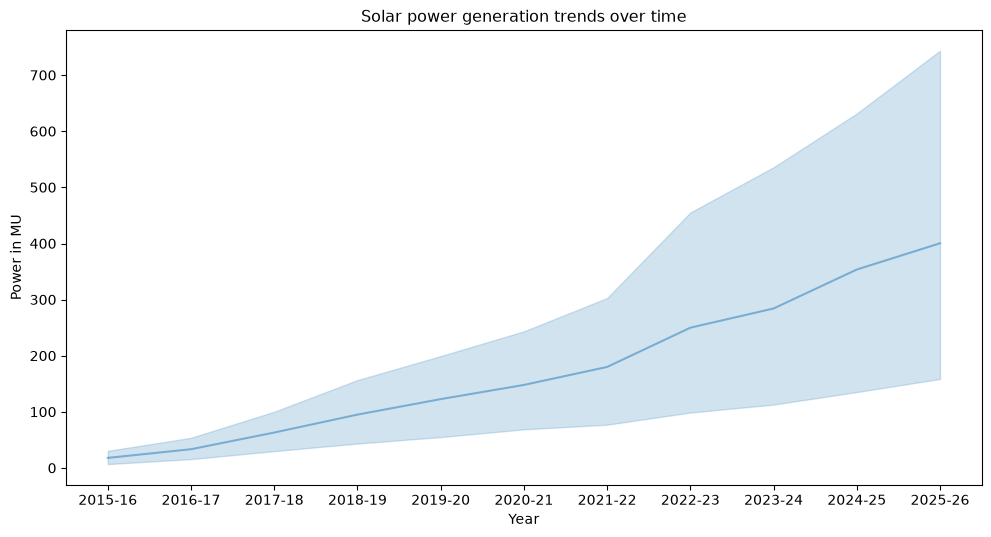

In [10]:
plt.figure(figsize=(12,6))
sns.lineplot(x=trends_df.fyear, y=trends_df.generation_mu, alpha=0.5)
plt.title('Solar power generation trends over time')
plt.xlabel('Year')
plt.ylabel('Power in MU')
plt.show()

Demand trends over years

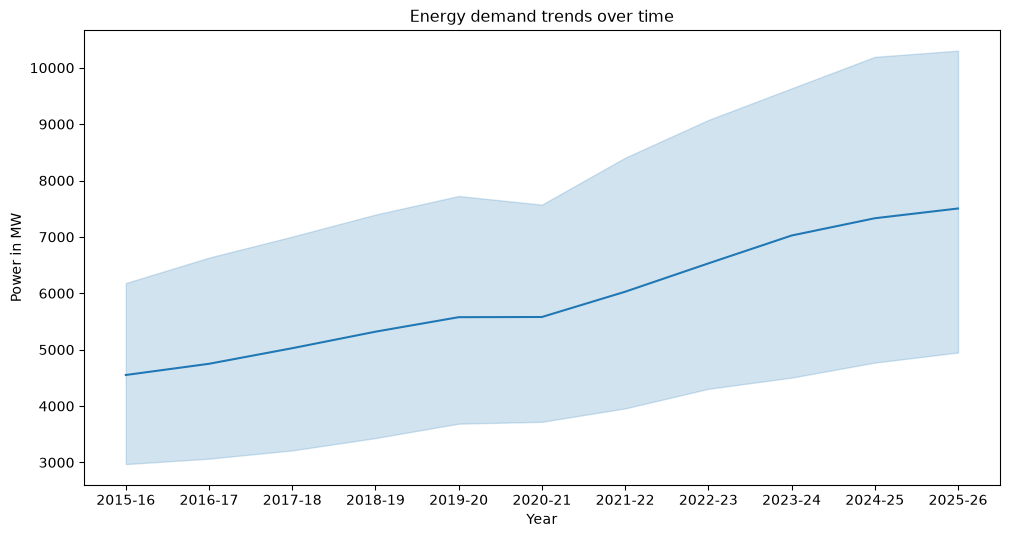

In [12]:
plt.figure(figsize=(12,6))
sns.lineplot(x=trends_df.fyear, y=trends_df.peak_demand_mw)
plt.title('Energy demand trends over time')
plt.xlabel('Year')
plt.ylabel('Power in MW')
plt.show()

Installed solar power capacity over time

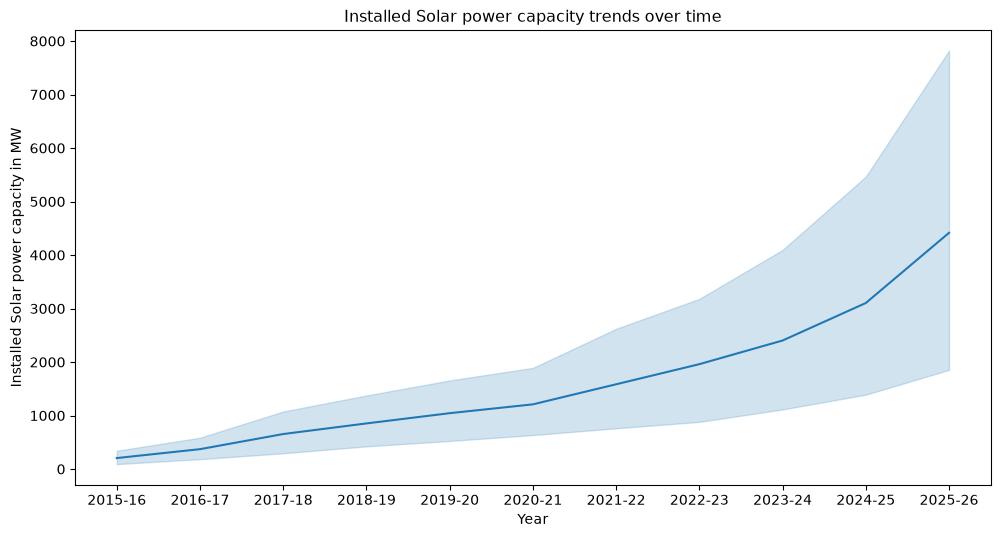

In [14]:
plt.figure(figsize=(12,6))
sns.lineplot(x=trends_df.fyear, y=trends_df.capacity_mw)
plt.title('Installed Solar power capacity trends over time')
plt.xlabel('Year')
plt.ylabel('Installed Solar power capacity in MW')
plt.show()

Curtailment trends over years

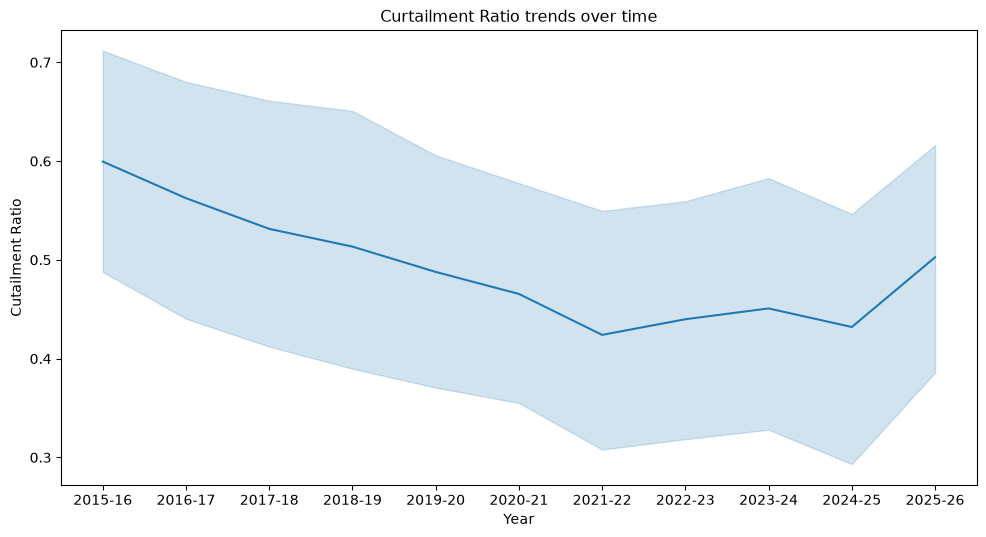

In [13]:
plt.figure(figsize=(12,6))
sns.lineplot(x=trends_df.fyear, y=trends_df.curtailment_ratio)
plt.title('Curtailment Ratio trends over time')
plt.xlabel('Year')
plt.ylabel('Cutailment Ratio')
plt.show()

Top States with Generation Potential & Actual generation

In [15]:
generation_df = df.groupby('state', as_index=False)[['generation_mu','potential_generation_mu']].mean().sort_values('generation_mu', ascending=False)
generation_df = generation_df.reset_index(drop=True)
generation_df['mean_gap'] = generation_df.potential_generation_mu - generation_df.generation_mu
generation_df = generation_df.rename(columns={
    'generation_mu': 'mean_generation_mu',
    'potential_generation_mu': 'mean_potential_generation_mu',

})
top_gen_df = generation_df.head(10)
top_gen_df


,state,mean_generation_mu,mean_potential_generation_mu,mean_gap
0,Rajasthan,1669.052109,1426.773543,-242.278566
1,Karnataka,824.105504,750.365574,-73.739930
2,Gujarat,648.207054,913.909939,265.702885
3,Tamil Nadu,604.123701,611.435404,7.311703
4,Andhra Pradesh,484.216220,423.668213,-60.548008
5,Telangana,440.602791,411.541975,-29.060816
6,Madhya Pradesh,313.086406,296.806536,-16.279871
7,Maharashtra,297.375891,491.438915,194.063024
8,Uttar Pradesh,195.088750,190.270781,-4.817969
9,Punjab,126.282248,110.663731,-15.618517


Top States with Mean Solar Power Installed Capacity 



In [16]:
top_cap_df = df.groupby('state', as_index=False)['capacity_mw'].mean().reset_index(drop=True).sort_values('capacity_mw', ascending=False)
top_cap_df.head(10)

,state,capacity_mw
26,Rajasthan,12197.411797
9,Gujarat,7853.999070
14,Karnataka,6452.332093
28,Tamil Nadu,5219.606693
18,Maharashtra,4364.495581
0,Andhra Pradesh,3760.076693
29,Telangana,3618.690698
17,Madhya Pradesh,2697.119922
31,Uttar Pradesh,1830.501016
25,Punjab,1041.008837


Top states curtailing solar generation due to various factors

In [17]:
curtailment_df = df.groupby('state', as_index=False)[['curtailment_proxy_mu', 'curtailment_ratio']].mean().sort_values('curtailment_proxy_mu', ascending=False).reset_index(drop=True)
curtailment_df.head(10)

,state,curtailment_proxy_mu,curtailment_ratio
0,Gujarat,271.295178,0.231858
1,Maharashtra,200.353499,0.242250
2,Karnataka,63.062898,0.163602
3,Rajasthan,56.828155,0.068135
4,Haryana,47.339137,0.579444
5,Tamil Nadu,39.626068,0.126265
6,Chhattisgarh,27.108453,0.431565
7,Uttarakhand,22.260432,0.496657
8,Madhya Pradesh,21.150925,0.051213
9,Andhra Pradesh,20.151946,0.096176


In [18]:
test = df.groupby('state').agg(
    n_rows=('curtailment_proxy_mu', 'count'),
    mean_proxy_mu=('curtailment_proxy_mu', 'mean'),
    mean_ratio=('curtailment_ratio', 'mean')
).sort_values('mean_proxy_mu', ascending=False).head(10)

In [19]:
test

,n_rows,mean_proxy_mu,mean_ratio
state,,,
Gujarat,129,271.295178,0.231858
Maharashtra,129,200.353499,0.242250
Karnataka,129,63.062898,0.163602
Rajasthan,128,56.828155,0.068135
Haryana,129,47.339137,0.579444
Tamil Nadu,127,39.626068,0.126265
Chhattisgarh,128,27.108453,0.431565
Uttarakhand,129,22.260432,0.496657
Madhya Pradesh,128,21.150925,0.051213


=== TOP 10 STATES BY MEAN PROXY CURTAILMENT (MU) ===
         state  n_months  mean_proxy_mu  total_proxy_mu  mean_ratio  median_ratio  share_of_top10_proxy_mu
       Gujarat       129     271.295178    34997.078000    0.231858      0.216986                 0.353509
   Maharashtra       129     200.353499    25845.601313    0.242250      0.204224                 0.261069
     Karnataka       129      63.062898     8135.113833    0.163602      0.000000                 0.082174
     Rajasthan       128      56.828155     7274.003812    0.068135      0.000000                 0.073475
       Haryana       129      47.339137     6106.748616    0.579444      0.654740                 0.061685
    Tamil Nadu       127      39.626068     5032.510630    0.126265      0.029047                 0.050834
  Chhattisgarh       128      27.108453     3469.881984    0.431565      0.416435                 0.035050
   Uttarakhand       129      22.260432     2871.595687    0.496657      0.502635          

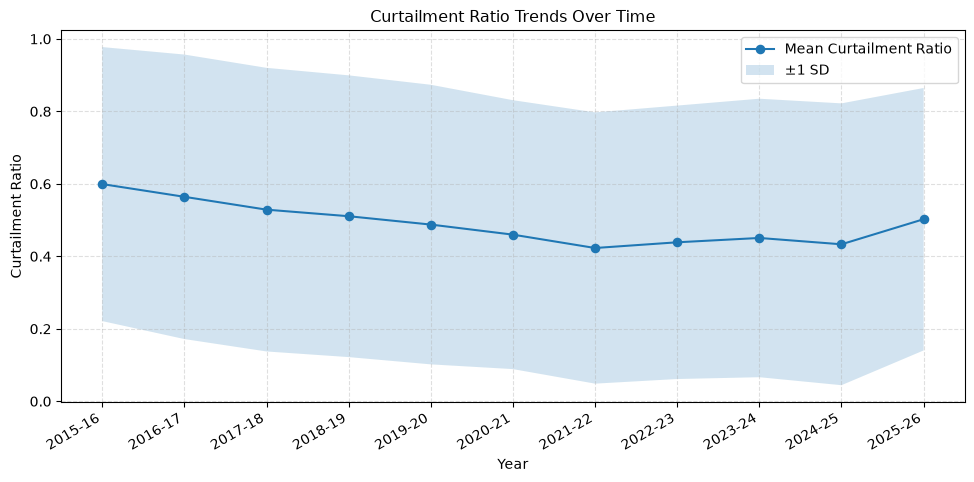

In [20]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Top 10 states summary (row counts, means, cumulative proxy MU)
top10_summary = (
    df.groupby("state", as_index=False)
    .agg(
        n_months=("curtailment_proxy_mu", "count"),
        mean_proxy_mu=("curtailment_proxy_mu", "mean"),
        total_proxy_mu=("curtailment_proxy_mu", "sum"),
        mean_ratio=("curtailment_ratio", "mean"),
        median_ratio=("curtailment_ratio", "median"),
    )
    .sort_values("mean_proxy_mu", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

top10_summary["share_of_top10_proxy_mu"] = (
    top10_summary["total_proxy_mu"] / top10_summary["total_proxy_mu"].sum()
)

print("=== TOP 10 STATES BY MEAN PROXY CURTAILMENT (MU) ===")
print(top10_summary.to_string(index=False))

print(
    f"\nTop 10 cumulative proxy MU: {top10_summary['total_proxy_mu'].sum():,.2f} MU"
)
print(
    f"Top 2 share of Top 10 proxy MU: "
    f"{top10_summary.loc[:1, 'share_of_top10_proxy_mu'].sum():.1%}"
)

# 2. Check extreme monthly ratios (helpful for states like Haryana, Uttarakhand, Chhattisgarh)
print("\n=== TOP 10 HIGHEST MONTHLY CURTAILMENT RATIOS ===")
ratio_cols = [c for c in ["state", "year", "month", "date", "curtailment_proxy_mu", "curtailment_ratio"] if c in df.columns]
print(
    df.sort_values("curtailment_ratio", ascending=False)[ratio_cols]
    .head(10)
    .to_string(index=False)
)

# 3. Annual trend summary & clean plot (if an 'fyear' / 'year' / 'period' column exists)
period_col = next((c for c in ["fyear", "financial_year", "year", "period"] if c in df.columns), None)

if period_col is not None:
    yearly = (
        df.groupby(period_col, as_index=False)["curtailment_ratio"]
        .agg(n_obs="count", mean="mean", std="std")
        .sort_values(period_col)
    )
    yearly["lower"] = yearly["mean"] - yearly["std"]
    yearly["upper"] = yearly["mean"] + yearly["std"]

    print(f"\n=== YEARLY CURTAILMENT RATIO ({period_col}) ===")
    print(yearly.to_string(index=False))

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(yearly[period_col].astype(str), yearly["mean"], marker="o", label="Mean Curtailment Ratio")
    ax.fill_between(
        yearly[period_col].astype(str),
        yearly["lower"],
        yearly["upper"],
        alpha=0.2,
        label="±1 SD",
    )
    ax.set_title("Curtailment Ratio Trends Over Time")
    ax.set_xlabel("Year")
    ax.set_ylabel("Curtailment Ratio")
    ax.legend()
    ax.grid(True, linestyle="--", alpha=0.4)
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

In [21]:
# Check share of zeros and ones in curtailment_ratio
print("Share == 0:", (df["curtailment_ratio"] == 0).mean())
print("Share == 1:", (df["curtailment_ratio"] == 1).mean())

# Check monthly counts inside 2025-26 (if a month/date column exists)
f25 = df[df["fyear"] == "2025-26"]
print("2025-26 rows:", len(f25), "| unique states:", f25["state"].nunique() if "state" in f25 else None)

Share == 0: 0.21264367816091953
Share == 1: 0.16712643678160918
2025-26 rows: 306 | unique states: 34
